In [ ]:
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import matplotlib.pyplot as plt
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    fbeta_score,
    make_scorer
)
from sklearn.inspection import permutation_importance
from pathlib import Path
import sys
sys.path.append('..')
from src.preparacao import carregar_dados

caminho = Path('../data/TESTE_ML_COM_TAXAS_INFRA.csv')
df = carregar_dados(caminho)
df['enquadro'] = pd.NA

df.loc[df['evasao'] == 0.0, 'enquadro'] = 0

df.loc[df['evasao'] >= 0.1, 'enquadro'] = 1

df['enquadro'] = df['enquadro'].astype('Int64')

display(df.head())

,cod_municipio,nome_municipio,perc_doc_sobrecarga,taxa_informal,taxa_climatizacao,taxa_internet,taxa_lab,media_alunos_por_sala,renda_pc,evasao,tx_repet,enquadro
0,4201273,Arabutã,34.6,41.70,100.00,100.00,71.43,15.1,2056.91,0.0,0.9,0
1,4201703,Ascurra,41.5,18.45,63.64,54.55,18.18,29.6,1713.62,3.9,4.8,1
2,4201950,Balneário Arroio do Silva,35.8,44.02,87.50,75.00,37.50,23.3,1530.60,3.0,2.3,1
3,4202578,Bom Jesus do Oeste,31.6,41.36,75.00,75.00,50.00,8.7,2347.75,1.8,1.8,1
4,4203154,Calmon,17.4,30.26,62.50,75.00,25.00,22.2,1031.92,6.1,1.5,1


In [ ]:
colunas_ml = ['perc_doc_sobrecarga','taxa_informal','tx_repet','renda_pc',
              'taxa_internet', 'taxa_climatizacao','taxa_lab','media_alunos_por_sala']

x = df[colunas_ml]
y = df['enquadro']

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('clf',   GradientBoostingClassifier(random_state=42))
])

param_grid = {
    'smote__k_neighbors':    [3, 5],           
    'clf__n_estimators':     [100, 200, 300, 400],
    'clf__learning_rate':    [0.05, 0.1],
    'clf__max_depth':        [2, 3, 4, 5, 6],
    'clf__min_samples_leaf': [5, 10, 15,20],
    'clf__subsample':        [0.8, 1.0],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

f2_scorer = make_scorer(fbeta_score, beta=2)


grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring=f2_scorer,       
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print("Melhores parâmetros:", grid.best_params_)
print(f"Melhor F2 (CV 5-fold): {grid.best_score_:.4f}")

df_resultados = pd.DataFrame(grid.cv_results_)

colunas_parametros = [col for col in df_resultados.columns if col.startswith('param_')]

colunas_finais = colunas_parametros + ['mean_test_score', 'rank_test_score']

display(df_resultados[colunas_finais].sort_values(by='rank_test_score'))

Fitting 5 folds for each of 640 candidates, totalling 3200 fits
Melhores parâmetros: {'clf__learning_rate': 0.1, 'clf__max_depth': 6, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 100, 'clf__subsample': 1.0, 'smote__k_neighbors': 3}
Melhor F2 (CV 5-fold): 0.9336


,param_clf__learning_rate,param_clf__max_depth,param_clf__min_samples_leaf,param_clf__n_estimators,param_clf__subsample,param_smote__k_neighbors,mean_test_score,rank_test_score
578,0.10,6,5,100,1.0,3,0.933626,1
524,0.10,5,5,400,0.8,3,0.931504,2
590,0.10,6,5,400,1.0,3,0.929834,3
586,0.10,6,5,300,1.0,3,0.929834,3
278,0.05,6,10,200,1.0,3,0.929770,5
...,...,...,...,...,...,...,...,...
39,0.05,2,15,200,1.0,5,0.871297,636
33,0.05,2,15,100,0.8,5,0.867809,637
48,0.05,2,20,100,0.8,3,0.867695,638
51,0.05,2,20,100,1.0,5,0.866535,639


,param_clf__learning_rate,param_clf__max_depth,param_clf__min_samples_leaf,param_clf__n_estimators,param_clf__subsample,param_smote__k_neighbors,mean_test_score,rank_test_score
578,0.10,6,5,100,1.0,3,0.933626,1
524,0.10,5,5,400,0.8,3,0.931504,2
590,0.10,6,5,400,1.0,3,0.929834,3
586,0.10,6,5,300,1.0,3,0.929834,3
278,0.05,6,10,200,1.0,3,0.929770,5
250,0.05,5,20,300,1.0,3,0.928539,6
292,0.05,6,15,200,0.8,3,0.928359,7
270,0.05,6,5,400,1.0,3,0.927714,8
582,0.10,6,5,200,1.0,3,0.926829,9
198,0.05,5,5,200,1.0,3,0.926013,10



Métricas finais:


,Métrica,Valor
0,F2-Score,0.9259
1,Acurácia,0.8644
2,Precisão,0.9091
3,Recall,0.9434


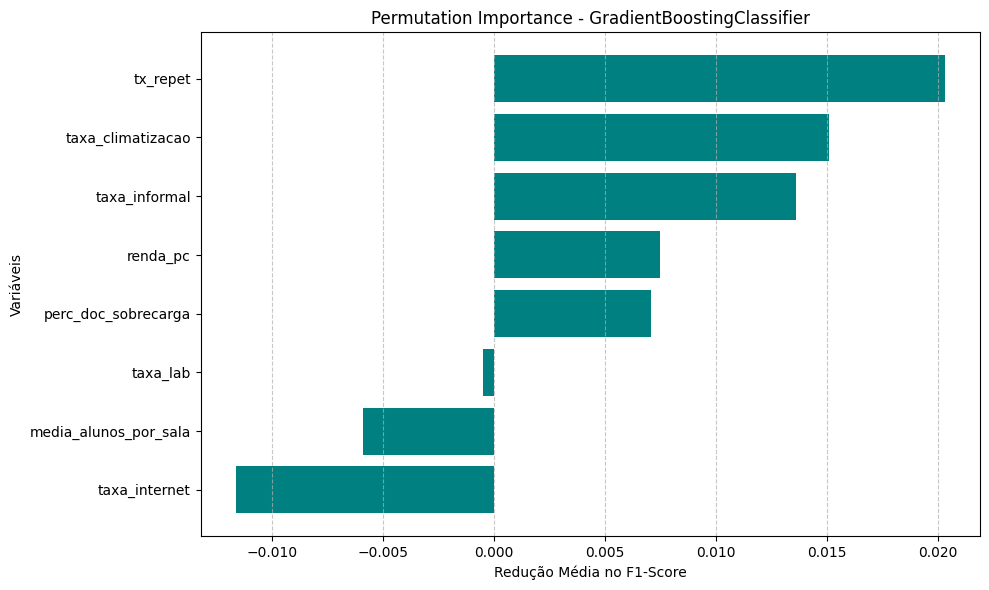

In [ ]:
df_top10 = df_resultados[colunas_finais].sort_values('rank_test_score').head(10)
display(df_top10)

melhor_modelo = grid.best_estimator_

melhor_modelo.fit(X_train, y_train)

y_pred = melhor_modelo.predict(X_test)

metricas_finais = pd.DataFrame({
    'Métrica': [
        'F2-Score',
        'Acurácia',
        'Precisão',
        'Recall'
    ],
    'Valor': [
        f1_score(y_test, y_pred, zero_division=0),
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0)
    ]
})

metricas_finais['Valor'] = metricas_finais['Valor'].round(4)

print('\nMétricas finais:')
display(metricas_finais)

permutation = permutation_importance(
    melhor_modelo,
    X_test,
    y_test,
    scoring='f1',
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

tabela_permutation_importance = pd.DataFrame({
    'Variável': X_test.columns,
    'Importância média': permutation.importances_mean,
    'Desvio padrão': permutation.importances_std
}).sort_values(
    by='Importância média',
    ascending=True
).reset_index(drop=True)

tabela_permutation_importance['Importância média'] = (
    tabela_permutation_importance['Importância média'].round(4)
)

tabela_permutation_importance['Desvio padrão'] = (
    tabela_permutation_importance['Desvio padrão'].round(4)
)


plt.figure(figsize=(10, 6))
plt.barh(
    tabela_permutation_importance['Variável'],
    tabela_permutation_importance['Importância média'],
    color='teal'
)
plt.title('Permutation Importance - GradientBoostingClassifier')
plt.xlabel('Redução Média no F1-Score')
plt.ylabel('Variáveis')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
